In [21]:
import pandas as pd
import numpy as np
from pvlib.location import Location
from pvlib.irradiance import get_total_irradiance

In [22]:
df_weather_1min = pd.read_csv(f'Data/Munich_weather_1min.csv')

# Rename frst colum to timestamp and set as index in df_weather_1min
df_weather_1min['timestamp'] = df_weather_1min['Unnamed: 0']
df_weather_1min = df_weather_1min.drop(columns=['Unnamed: 0'])
df_weather_1min['timestamp'] = pd.to_datetime(df_weather_1min['timestamp'])
df_weather_1min.set_index('timestamp', inplace=True)


df_weather_12h = pd.read_csv(f'Data/Munich_weather_12h.csv')
# Remove Unnamed: 0 column from df_weather_12h and df_weather_1min
df_weather_12h = df_weather_12h.drop(columns=['Unnamed: 0'])

# Add timestamp colum to df_weather_12h starting from '2013-01-01 00:00:00' with frequency of 12 hours
df_weather_12h['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_weather_12h), freq='12h')
df_weather_12h['timestamp'] = pd.to_datetime(df_weather_12h['timestamp'])
df_weather_12h.set_index('timestamp', inplace=True)

In [30]:
# 1. CONFIGURATION
#  Location (Munich Campus)
lat, lon = 48.14904043542013, 11.567681331388638
altitude = 519 

surface_tilt = 30 
surface_azimuth = 180  # (south)

# Define the full year time index (1-minute resolution)
times = pd.date_range(start='2013-01-01 00:00:00', end='2013-12-31 23:59:00', freq='1min')

# 2. GENERATE REFERENCE CLEAR SKY POA
site = Location(lat, lon, altitude=altitude, name='Munich Campus')

# Calcultae solar position
solar_position = site.get_solarposition(times)

# Calculate Clear Sky GHI/DNI/DHI
cs = site.get_clearsky(times)

# Transpose Clear Sky Data to Plane of Array (POA)
cs_poa = get_total_irradiance(
    surface_tilt,
    surface_azimuth,
    solar_position['apparent_zenith'],
    solar_position['azimuth'],
    cs['dni'],
    cs['ghi'],
    cs['dhi']
)

# We only care about the total radiation 
reference_poa = cs_poa['poa_global']

# 3. PROCESS USER DATA
df_weather_12h = pd.read_csv(f'Data/Munich_weather_12h.csv')
df_weather_12h = df_weather_12h.drop(columns=['Unnamed: 0'])
df_weather_12h['timestamp'] = pd.date_range(start='2013-01-01 00:00:00', periods=len(df_weather_12h), freq='12h')
df_weather_12h = df_weather_12h.set_index('timestamp')

# 4. DOWNSCALING RADIATION (Stochastic Method)

# Resample reference to 12h to macht input data
ref_12h = reference_poa.resample('12h').mean()

# Calculate Clearness Index
df_combined = pd.concat([df_weather_12h['G_Gk'], ref_12h], axis=1)

# If Reference is 0, Kt is 0
df_combined['Kt'] = df_combined['G_Gk'] / df_combined['poa_global'].replace(0, np.nan)
df_combined['Kt'] = df_combined['Kt'].fillna(0).clip(0, 1.2)

# Upsample Kt to 1-minute resolution
Kt_1min = df_combined['Kt'].reindex(times).ffill()

# Apply Base Calculation (Reference * Kt)
poa_1min = reference_poa * Kt_1min

# Add Stochastic Noise (Clouds)
daylight_mask = (reference_poa > 10)
cloudy_mask = (Kt_1min > 0.2) & (Kt_1min < 0.8)

# Generate noise
noise_intensity = 0.3
smoothing_window = 10  # in minutes

noise_scale = noise_intensity * (1 - abs(Kt_1min - 0.5) * 2)
random_noise = np.random.normal(0, 1, size=len(times))

# Smooth the noise (clouds dont flicker instantly every minute)
smoothed_noise = pd.Series(random_noise, index=times).rolling(smoothing_window, min_periods=1, center=True).mean()

# Apply noise 
final_poa = poa_1min.copy()
final_poa[daylight_mask & cloudy_mask] *= (1 + smoothed_noise[daylight_mask & cloudy_mask] * noise_scale[daylight_mask & cloudy_mask])
# Final Cleanup
final_poa = final_poa.clip(lower=0)

# Since Temp doesn't jump like light, we use PCHIP interpolation
df_temp_centered = df_weather_12h[['Ta']].copy()

# Shift the index forward by 6 hours (half of the 12h resolution)
# 00:00 becomes 06:00, 12:00 becomes 18:00
df_temp_centered.index = df_temp_centered.index + pd.Timedelta(hours=3)

# --- 6. DOWNSCALE TEMPERATURE (With Amplitude Boost) ---
print("Downscaling Temperature with Amplitude Correction...")

# 1. Standard Interpolation (as before)
temp_base = df_temp_centered['Ta'].reindex(times).interpolate(method='pchip', limit_direction='both')

# 2. AMPLITUDE CORRECTION
# We calculate the rolling 24h mean to find the "center" of the day
temp_rolling_mean = temp_base.rolling(window=1440, center=True, min_periods=1).mean()

# [KNOB] Increase this factor to stretch the peaks and valleys
# 1.0 = No change
# 1.5 = 50% more amplitude
amp_factor = 2.0

# Calculate the deviation from the mean and multiply it by our factor
temp_stretched = temp_rolling_mean + (temp_base - temp_rolling_mean) * amp_factor

# 3. Add tiny thermal noise for texture
temp_final = temp_stretched + np.random.normal(0, 0.05, len(times))

# --- 6. EXPORT ---
df_result = pd.DataFrame({
    'POA_Global_Wm2': final_poa,
    'T_Ambient_C': temp_final
}, index=times)

print("Done! First 5 rows:")
print(df_result.head())


Downscaling Temperature with Amplitude Correction...
Done! First 5 rows:
                     POA_Global_Wm2  T_Ambient_C
2013-01-01 00:00:00             0.0     0.669864
2013-01-01 00:01:00             0.0     0.801714
2013-01-01 00:02:00             0.0     0.740621
2013-01-01 00:03:00             0.0     0.852170
2013-01-01 00:04:00             0.0     0.835945


### Plot interpolated data

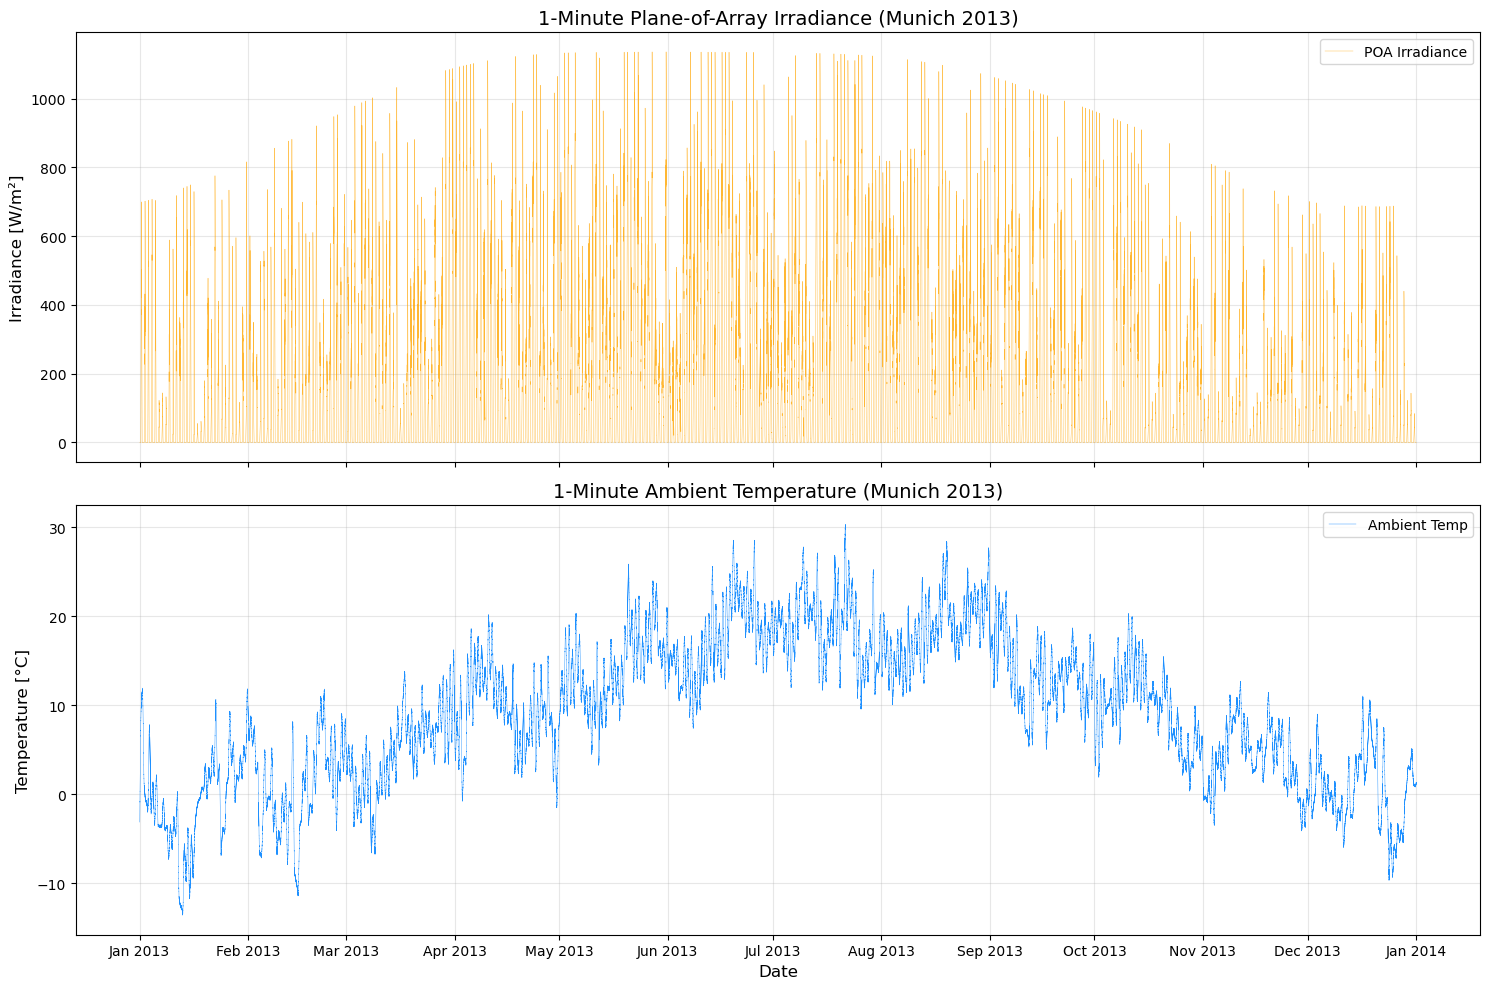

In [24]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Set up the figure with 2 subplots sharing the same X-axis (Time)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# --- Plot 1: Solar Radiation (POA) ---
# We use orange for solar data
ax1.plot(df_result.index, df_result['POA_Global_Wm2'], 
         color='orange', linewidth=0.3, alpha=0.8, label='POA Irradiance')

ax1.set_ylabel('Irradiance [W/m²]', fontsize=12)
ax1.set_title('1-Minute Plane-of-Array Irradiance (Munich 2013)', fontsize=14)
ax1.legend(loc='upper right')
ax1.grid(True, which='both', alpha=0.3)

# --- Plot 2: Ambient Temperature ---
# We use blue for temperature
ax2.plot(df_result.index, df_result['T_Ambient_C'], 
         color='dodgerblue', linewidth=0.3, label='Ambient Temp')

ax2.set_ylabel('Temperature [°C]', fontsize=12)
ax2.set_title('1-Minute Ambient Temperature (Munich 2013)', fontsize=14)
ax2.legend(loc='upper right')
ax2.grid(True, which='both', alpha=0.3)

# --- Formatting the X-Axis (Dates) ---
# Show Month and Year on the axis
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax2.xaxis.set_major_locator(mdates.MonthLocator())

plt.xlabel('Date', fontsize=12)
plt.tight_layout()

# Save the plot or show it
# plt.savefig('Munich_2013_FullYear.png', dpi=300) # Uncomment to save high-res
plt.show()

### Compare 1-min data with full year downscaled 1-min data

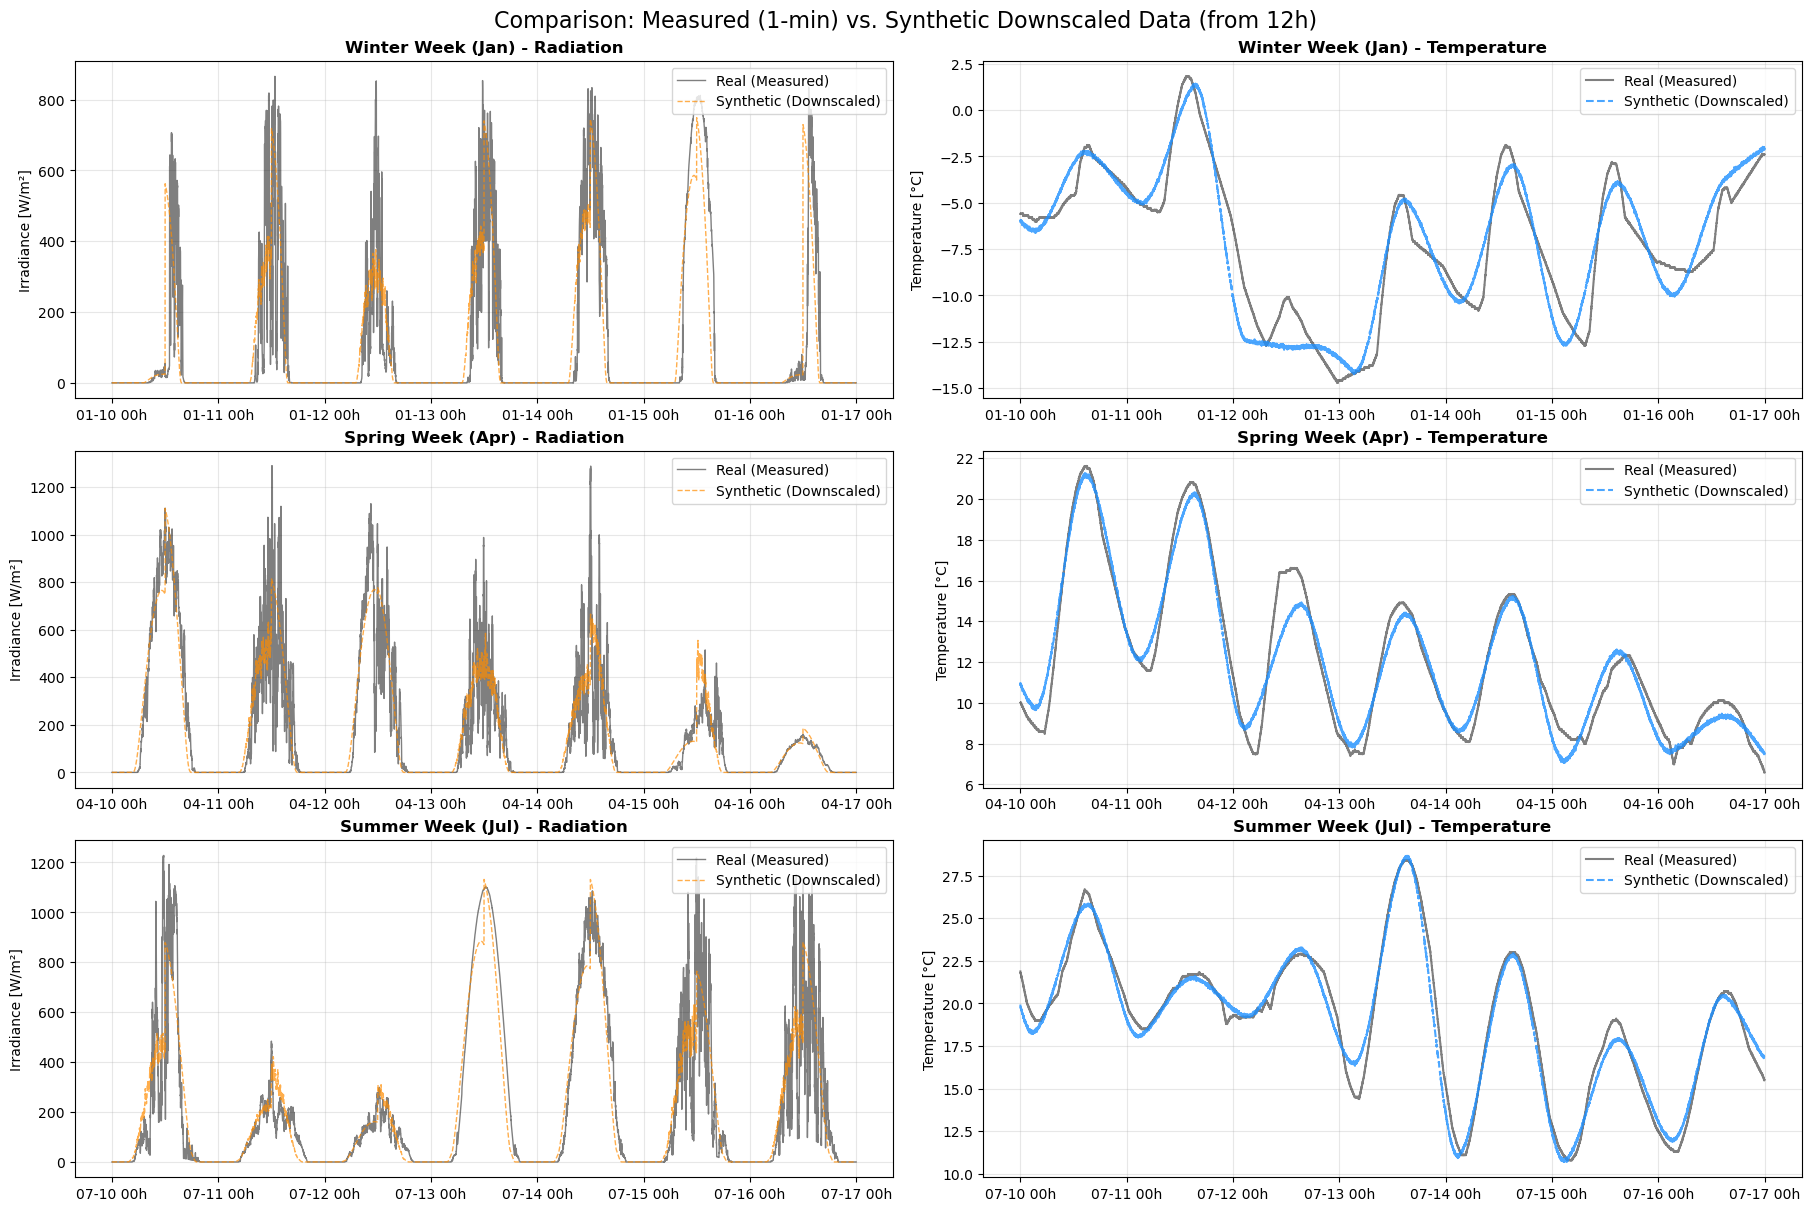

In [31]:
# --- CONFIGURATION ---
# Define the column names for your REAL dataframe
col_rad_real = 'G_Gk'  # Replace if your column name is different
col_temp_real = 'Ta'    # Replace if your column name is different

# Define the column names for the SYNTHETIC dataframe (from previous step)
col_rad_synth = 'POA_Global_Wm2'
col_temp_synth = 'T_Ambient_C'

# Define 3 representative weeks (Winter, Spring, Summer)
# Format: (Start_Date, End_Date, Title_Label)
weeks = [
    ('2013-01-10', '2013-01-16', 'Winter Week (Jan)'),
    ('2013-04-10', '2013-04-16', 'Spring Week (Apr)'),
    ('2013-07-10', '2013-07-16', 'Summer Week (Jul)')
]

# --- PLOTTING ---
# Create a 3x2 grid (3 Weeks rows x 2 Metrics columns)
fig, axes = plt.subplots(3, 2, figsize=(18, 12), constrained_layout=True)

for i, (start, end, label) in enumerate(weeks):
    # Slice the dataframes for the specific week
    # We use .loc[start:end] to slice by index (DatetimeIndex)
    real_slice = df_weather_1min.loc[start:end]
    synth_slice = df_result.loc[start:end]
    
    # --- LEFT COLUMN: RADIATION ---
    ax_rad = axes[i, 0]
    
    # Plot Real Data (Black/Grey for Ground Truth)
    ax_rad.plot(real_slice.index, real_slice[col_rad_real], 
                color='black', alpha=0.5, linewidth=1, label='Real (Measured)')
    
    # Plot Synthetic Data (Orange for Simulation)
    ax_rad.plot(synth_slice.index, synth_slice[col_rad_synth], 
                color='darkorange', alpha=0.7, linewidth=1, linestyle='--', label='Synthetic (Downscaled)')
    
    ax_rad.set_title(f"{label} - Radiation", fontsize=12, fontweight='bold')
    ax_rad.set_ylabel("Irradiance [W/m²]")
    ax_rad.legend(loc='upper right', frameon=True)
    ax_rad.grid(True, alpha=0.3)
    
    # --- RIGHT COLUMN: TEMPERATURE ---
    ax_temp = axes[i, 1]
    
    # Plot Real Data
    ax_temp.plot(real_slice.index, real_slice[col_temp_real], 
                 color='black', alpha=0.5, linewidth=1.5, label='Real (Measured)')
    
    # Plot Synthetic Data
    ax_temp.plot(synth_slice.index, synth_slice[col_temp_synth], 
                 color='dodgerblue', alpha=0.8, linewidth=1.5, linestyle='--', label='Synthetic (Downscaled)')
    
    ax_temp.set_title(f"{label} - Temperature", fontsize=12, fontweight='bold')
    ax_temp.set_ylabel("Temperature [°C]")
    ax_temp.legend(loc='upper right', frameon=True)
    ax_temp.grid(True, alpha=0.3)
    
    # Date Formatting for X-Axis
    date_fmt = mdates.DateFormatter('%m-%d %Hh')
    ax_rad.xaxis.set_major_formatter(date_fmt)
    ax_temp.xaxis.set_major_formatter(date_fmt)

# Main Title
fig.suptitle('Comparison: Measured (1-min) vs. Synthetic Downscaled Data (from 12h)', fontsize=16)

# Save or Show
# plt.savefig('Comparison_Real_vs_Synthetic.png', dpi=300)
plt.show()